# LGD Modeling: Two-Stage, Beta & Fractional Regression

> **What it does:** estimates loss given default on 260,000 charged-off Lending Club consumer loans. It measures realised LGD from the recovery cash flows, shows how incomplete workouts bias recent vintages, and compares six LGD models out of time: a grade lookup table, OLS, fractional logit, beta regression, a two-stage (zero-recovery + severity) model and LightGBM. It ends with a downturn view of LGD against U.S. unemployment.
> **Data:** Lending Club accepted loans 2007–2018 (Kaggle `wordsforthewise/lending-club`), filtered and aggregated with DuckDB; U.S. unemployment rate (FRED).
> **Methods:** workout-LGD definition; resolution-bias analysis; OLS; Papke–Wooldridge fractional logit (quasi-binomial GLM); beta regression with the Smithson–Verkuilen squeeze; two-stage hurdle model; LightGBM with a cross-entropy objective; out-of-time validation with RMSE, MAE, rank correlation, calibration by decile and loss-weighted accuracy; downturn LGD.
> **Key output:** the realised LGD distribution; out-of-time accuracy by model; drivers of recovery; and the downturn add-on.

## 1. Why LGD is hard

Expected loss is $PD \times LGD \times EAD$, and in the Basel IRB formula capital is roughly proportional to LGD. Yet LGD is the weakest of the three parameters in most banks:

- **The distribution is not normal.** Realised LGD lives in $[0,1]$ and is usually **bimodal**: many loans recover nothing, and the rest spread out. OLS predictions can fall outside the interval and its errors are badly heteroscedastic.
- **It takes years to observe.** Recoveries arrive long after default. Loans that defaulted recently have incomplete workouts and look worse than they will end up, which is **resolution bias**.
- **It is cyclical.** Recoveries fall when collateral values and borrowers' incomes fall, which is why the IRB framework asks for a **downturn LGD**.

Unsecured consumer credit is the cleanest place to see all three effects, and Lending Club publishes the recovery cash flows loan by loan.

## 2. Models

| Model | Idea |
|---|---|
| Grade lookup | average realised LGD by sub-grade: what many banks still use |
| OLS | linear regression, predictions clipped to $[0,1]$ |
| Fractional logit | $E[\text{LGD}\mid x]=\Lambda(x'\beta)$, estimated by quasi-maximum likelihood with a binomial deviance (Papke & Wooldridge, 1996). Consistent for any distribution on $[0,1]$, including exact 0s and 1s |
| Beta regression | LGD $\sim \text{Beta}(\mu\phi,(1-\mu)\phi)$ with logit$(\mu)=x'\beta$. Needs values strictly inside $(0,1)$, so the outcome is squeezed: $(y(n-1)+0.5)/n$ |
| Two-stage | stage 1: logistic model for $P(\text{LGD}=1)$, i.e. no net recovery at all; stage 2: fractional logit on the loans with some recovery; $E[\text{LGD}]=p_1+(1-p_1)\,\mu_2$ |
| LightGBM | gradient boosting with the cross-entropy objective, which accepts targets in $[0,1]$ |

## 3. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import) ---------------
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the kernel crashed".
import os
os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library ---------------------------------------------------------
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party ---------------------------------------------------------------
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import duckdb
import lightgbm as lgb
import statsmodels.api as sm
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, roc_auc_score
from statsmodels.othermod.betareg import BetaModel

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError("FRED_API_KEY not found. Create the .env file at the repo root (see .env.example).")
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {"User-Agent": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0 Safari/537.36"}

SEED = 11
KAGGLE_DATASET, LC_FILE = "wordsforthewise/lending-club", "accepted_2007_to_2018Q4.csv.gz"
TRAIN_YEARS, TEST_YEAR = (2010, 2015), 2016    # by year of default (last payment); later defaults have incomplete workouts

print(f"statsmodels {sm.__version__} · lightgbm {lgb.__version__} · duckdb {duckdb.__version__} · run on {dt.date.today():%Y-%m-%d}")

statsmodels 0.15.0 · lightgbm 4.7.0 · duckdb 1.5.6 · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours ----------
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if path.exists() and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours:
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(f"⚠️  {name}: download failed ({type(err).__name__}); using cached copy")
            return pd.read_parquet(path)
        raise


# --- Chart style -------------------------------------------------------------------------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": INK_2, "ytick.color": INK_2,
    "legend.frameon": False, "lines.linewidth": 2.0, "font.size": 10, "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """Interactive HTML always; static PNG (for GitHub) when kaleido can find Chrome."""
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run `plotly_get_chrome` once.")


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"

# --- Kaggle downloads ------------------------------------------------------------------------
# The kaggle package authenticates with KAGGLE_API_TOKEN (read from .env above) or with
# ~/.kaggle/access_token / ~/.kaggle/kaggle.json. It is imported here, after load_dotenv, on purpose.
import zipfile


def kaggle_api():
    from kaggle.api.kaggle_api_extended import KaggleApi
    api = KaggleApi()
    api.authenticate()
    return api


def kaggle_file(ref, filename, competition=False):
    """Download one file of a Kaggle dataset or competition into data/ (once) and return its local path."""
    target = DATA_DIR / filename
    if target.exists():
        return target
    api = kaggle_api()
    if competition:
        api.competition_download_file(ref, filename, path=DATA_DIR, quiet=True)
    else:
        api.dataset_download_file(ref, filename, path=DATA_DIR, quiet=True)
    zipped = DATA_DIR / f"{Path(filename).name}.zip"
    if zipped.exists():                                    # large files arrive zipped
        with zipfile.ZipFile(zipped) as z:
            z.extractall(DATA_DIR)
        zipped.unlink()
    if not target.exists():
        raise FileNotFoundError(f"{filename} not found after download from {ref}")
    return target

## 4. Data: realised LGD from the recovery cash flows

The full file has 2.26 million loans and 151 columns (390 MB compressed). DuckDB reads it directly and keeps only the 269,000 charged-off loans and the columns needed. For each loan:

- **EAD** = funded amount − principal repaid before charge-off (outstanding principal at default);
- **net recovery** = recoveries − collection fees;
- **LGD** = $1-\text{net recovery}/\text{EAD}$, capped to $[0,1]$.

The default date is not published. The **last payment date** is used as the date of default, which is when the loan stopped performing (charge-off follows about four months later).

In [3]:
def fetch_charged_off():
    path = kaggle_file(KAGGLE_DATASET, LC_FILE)
    con = duckdb.connect()
    con.execute("SET enable_progress_bar = false")
    return con.execute(f"""
        SELECT id, CAST(funded_amnt AS DOUBLE) AS funded_amnt, CAST(total_rec_prncp AS DOUBLE) AS total_rec_prncp,
               CAST(recoveries AS DOUBLE) AS recoveries, CAST(collection_recovery_fee AS DOUBLE) AS collection_recovery_fee,
               term, CAST(int_rate AS DOUBLE) AS int_rate, grade, sub_grade, emp_length, home_ownership,
               CAST(annual_inc AS DOUBLE) AS annual_inc, verification_status, purpose, addr_state,
               CAST(dti AS DOUBLE) AS dti, CAST(fico_range_low AS DOUBLE) AS fico, CAST(revol_util AS DOUBLE) AS revol_util,
               CAST(open_acc AS DOUBLE) AS open_acc, CAST(total_acc AS DOUBLE) AS total_acc, CAST(mort_acc AS DOUBLE) AS mort_acc,
               CAST(pub_rec_bankruptcies AS DOUBLE) AS bankruptcies, CAST(installment AS DOUBLE) AS installment,
               initial_list_status, application_type, issue_d, last_pymnt_d, debt_settlement_flag
        FROM read_csv_auto('{path.as_posix()}', sample_size=-1, ignore_errors=true)
        WHERE loan_status LIKE '%Charged Off'
        ORDER BY id""").df()                                # deterministic row order


raw = cached("lc_charged_off", fetch_charged_off, max_age_hours=24 * 365)
d = raw.copy()
d["issue"] = pd.to_datetime(d["issue_d"], format="%b-%Y")
d["default_date"] = pd.to_datetime(d["last_pymnt_d"], format="%b-%Y").fillna(d["issue"])   # never paid: defaulted at issue
d["EAD"] = d["funded_amnt"] - d["total_rec_prncp"]
d = d[d["EAD"] > 50].copy()
d["net_recovery"] = d["recoveries"] - d["collection_recovery_fee"]
d["LGD"] = (1 - d["net_recovery"] / d["EAD"]).clip(0, 1)
d["no_recovery"] = (d["net_recovery"] <= 0).astype(int)
d["default_year"] = d["default_date"].dt.year
print(f"{len(raw):,} charged-off loans · {len(d):,} with positive EAD · mean LGD {d['LGD'].mean():.1%} · "
      f"EAD-weighted {np.average(d['LGD'], weights=d['EAD']):.1%} · no net recovery {d['no_recovery'].mean():.1%}")

269,320 charged-off loans · 269,239 with positive EAD · mean LGD 90.9% · EAD-weighted 91.0% · no net recovery 31.1%


### Resolution bias

The data were extracted at the end of 2018. Loans that defaulted in 2018 had little time to recover anything, so their LGD looks far worse. The model sample therefore stops at defaults in 2016: 2010–2015 train the models and 2016 is the out-of-time test. 2017 onward is shown only as evidence of the bias.

In [4]:
vint = d.groupby("default_year").agg(loans=("LGD", "size"), mean_LGD=("LGD", "mean"), no_recovery=("no_recovery", "mean"),
                                     ead_mm=("EAD", lambda s: s.sum() / 1e6))
vint = vint[vint["loans"] >= 100]
vint.assign(mean_LGD=vint["mean_LGD"] * 100, no_recovery=vint["no_recovery"] * 100).rename(
    columns={"mean_LGD": "mean LGD %", "no_recovery": "no net recovery %", "ead_mm": "EAD $mm"}).round(1)

,loans,mean LGD %,no net recovery %,EAD $mm
default_year,,,,
2008,188,93.90,3.20,1.50
2009,405,93.60,4.00,3.20
2010,706,93.20,0.70,5.00
2011,1227,91.70,0.80,9.80
2012,2698,93.60,0.50,26.60
2013,6552,91.20,2.70,71.90
2014,15098,88.90,12.30,172.70
2015,31909,88.50,19.80,370.40
2016,61286,90.40,22.80,719.00


### Recovery channels

The recovery rate (net recovery / EAD) is not spread smoothly. It clusters at zero and between 5% and 20%, which is the signature of **debt sales**: Lending Club sold most charged-off loans to collection buyers at a price close to a fixed fraction of the balance. A smaller group recovers more through **settlements** negotiated with the borrower. The collection fee also changed: about 1% of recoveries before 2015 and 18% afterwards.

In [5]:
d["recovery_rate"] = 1 - d["LGD"]
d["channel"] = np.select([d["net_recovery"] <= 0, d["debt_settlement_flag"].eq("Y"), d["recovery_rate"] <= 0.2],
                         ["no recovery", "settlement", "debt sale / standard collection"], "high recovery (> 20%)")
d["fee_share"] = d["collection_recovery_fee"] / d["recoveries"].where(d["recoveries"] > 0)
ch = d[d["default_year"].between(2010, 2018)]
channels = pd.crosstab(ch["default_year"], ch["channel"], normalize="index").mul(100)
channel_lgd = ch.groupby("channel")["LGD"].agg(["size", "mean"]).rename(columns={"size": "loans", "mean": "mean LGD"})
print("Median collection fee / recoveries by year of default:",
      ch.groupby("default_year")["fee_share"].median().mul(100).round(0).astype(int).to_dict())
display(channel_lgd.assign(**{"mean LGD": channel_lgd["mean LGD"] * 100}).round(1))
channels.round(1)

Median collection fee / recoveries by year of default: {2010: 1, 2011: 1, 2012: 1, 2013: 1, 2014: 1, 2015: 18, 2016: 18, 2017: 18, 2018: 18}


,loans,mean LGD
channel,,
debt sale / standard collection,152216,89.60
high recovery (> 20%),3256,50.00
no recovery,81799,100.00
settlement,28801,75.50


channel,debt sale / standard collection,high recovery (> 20%),no recovery,settlement
default_year,,,,
2010,91.60,6.40,0.70,1.30
2011,89.00,8.40,0.80,1.80
2012,92.90,4.90,0.50,1.70
2013,92.00,4.00,2.70,1.40
2014,80.50,3.40,12.30,3.90
2015,72.50,1.30,19.80,6.40
2016,67.10,1.10,22.80,9.10
2017,55.00,1.00,29.40,14.70
2018,33.60,0.60,52.70,13.20


## 5. Features at the time of default

Everything known when the loan defaults: origination terms and borrower profile, plus two behavioural features, **months on book** before default and the **share of principal already repaid**. Debt-settlement status is an outcome of the workout, so it is not a feature.

In [6]:
d["months_on_book"] = ((d["default_date"] - d["issue"]).dt.days / 30.44).clip(lower=0)
d["repaid_share"] = d["total_rec_prncp"] / d["funded_amnt"]
d["term_60"] = d["term"].str.contains("60").astype(int)
d["grade_num"] = d["sub_grade"].map({f"{g}{i}": k * 5 + i for k, g in enumerate("ABCDEFG") for i in range(1, 6)})
d["emp_years"] = pd.to_numeric(d["emp_length"].str.extract(r"(\d+)")[0], errors="coerce")
d["log_income"] = np.log1p(d["annual_inc"])
d["log_ead"] = np.log(d["EAD"])
d["payment_to_income"] = d["installment"] * 12 / d["annual_inc"].where(d["annual_inc"] > 0)
d["whole_loan"] = (d["initial_list_status"] == "w").astype(int)
d["verified"] = (d["verification_status"] != "Not Verified").astype(int)
NUM = ["grade_num", "int_rate", "term_60", "log_ead", "repaid_share", "months_on_book", "fico", "dti", "revol_util", "log_income",
       "payment_to_income", "emp_years", "open_acc", "total_acc", "mort_acc", "bankruptcies", "whole_loan", "verified"]
CAT = ["home_ownership", "purpose"]

model_df = d[d["default_year"].between(TRAIN_YEARS[0], TEST_YEAR)].copy()
for c in NUM:
    model_df[c] = model_df[c].replace([np.inf, -np.inf], np.nan)
    model_df[c] = model_df[c].fillna(model_df[c].median())
model_df["home_ownership"] = model_df["home_ownership"].where(model_df["home_ownership"].isin(["MORTGAGE", "OWN"]), "RENT/OTHER")
top_purpose = model_df["purpose"].value_counts().index[:6]
model_df["purpose"] = model_df["purpose"].where(model_df["purpose"].isin(top_purpose), "other")
X_all = pd.get_dummies(model_df[NUM + CAT], columns=CAT, drop_first=True, dtype=float)
mu, sd = X_all[NUM].mean(), X_all[NUM].std()
X_all[NUM] = (X_all[NUM] - mu) / sd                                   # standardised: coefficients are comparable
X_all = X_all.loc[:, X_all[model_df["default_year"].between(*TRAIN_YEARS).to_numpy()].std() > 0]   # drop features constant in training
is_tr = model_df["default_year"].between(*TRAIN_YEARS).to_numpy()
is_te = (model_df["default_year"] == TEST_YEAR).to_numpy()
Xtr, Xte = sm.add_constant(X_all[is_tr], has_constant="add"), sm.add_constant(X_all[is_te], has_constant="add")
ytr, yte = model_df.loc[is_tr, "LGD"].to_numpy(), model_df.loc[is_te, "LGD"].to_numpy()
ead_te = model_df.loc[is_te, "EAD"].to_numpy()
print(f"train (defaults {TRAIN_YEARS[0]}–{TRAIN_YEARS[1]}): {is_tr.sum():,} loans, mean LGD {ytr.mean():.1%} · "
      f"test ({TEST_YEAR}): {is_te.sum():,}, mean LGD {yte.mean():.1%} · {Xtr.shape[1] - 1} regressors")

train (defaults 2010–2015): 58,190 loans, mean LGD 89.3% · test (2016): 61,286, mean LGD 90.4% · 25 regressors


## 6. Six models

In [7]:
preds, fitted = {}, {}

# 1. sub-grade lookup table
lookup = model_df[is_tr].groupby("sub_grade")["LGD"].mean()
preds["Sub-grade lookup"] = model_df.loc[is_te, "sub_grade"].map(lookup).fillna(ytr.mean()).to_numpy()

# 2. OLS
ols = sm.OLS(ytr, Xtr).fit()
preds["OLS"] = np.clip(ols.predict(Xte), 0, 1)

# 3. fractional logit (quasi-binomial GLM)
frac = sm.GLM(ytr, Xtr, family=sm.families.Binomial()).fit(cov_type="HC1")
preds["Fractional logit"] = frac.predict(Xte)
fitted["Fractional logit"] = frac

# 4. beta regression on the squeezed outcome
n = len(ytr)
y_sq = (ytr * (n - 1) + 0.5) / n
beta = BetaModel(y_sq, Xtr).fit(method="bfgs", maxiter=500, disp=0)
preds["Beta regression"] = beta.predict(Xte)
fitted["Beta regression"] = beta

# 5. two-stage: P(no recovery) x 1 + (1 - P) x severity of the loans with some recovery
z_tr = model_df.loc[is_tr, "no_recovery"].to_numpy()
stage1 = sm.GLM(z_tr, Xtr, family=sm.families.Binomial()).fit()
pos = z_tr == 0
stage2 = sm.GLM(ytr[pos], Xtr[pos], family=sm.families.Binomial()).fit(cov_type="HC1")
p1 = stage1.predict(Xte)
preds["Two-stage"] = p1 + (1 - p1) * stage2.predict(Xte)

# 6. LightGBM with a cross-entropy objective (targets in [0, 1]); raw features, categoricals native
lgb_X = model_df[NUM + CAT].copy()
for c in CAT:
    lgb_X[c] = lgb_X[c].astype("category")
inner = np.random.default_rng(SEED).random(is_tr.sum()) < 0.85
gbm = lgb.LGBMRegressor(objective="cross_entropy", n_estimators=3_000, learning_rate=0.03, num_leaves=31, min_child_samples=200,
                        subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=5.0, random_state=SEED, verbose=-1)
Xg_tr = lgb_X[is_tr]
gbm.fit(Xg_tr[inner], ytr[inner], eval_set=[(Xg_tr[~inner], ytr[~inner])], callbacks=[lgb.early_stopping(200, verbose=False)])
preds["LightGBM"] = gbm.predict(lgb_X[is_te])
print(f"LightGBM: {gbm.best_iteration_} trees · beta precision φ = {np.exp(beta.params.iloc[-1]):.2f} · "
      f"stage-1 share with no recovery (train) {z_tr.mean():.1%}")

LightGBM: 233 trees · beta precision φ = 3.07 · stage-1 share with no recovery (train) 14.4%


## 7. Out-of-time validation (defaults in 2016)

- **RMSE, MAE, R²** of loan-level LGD.
- **Spearman ρ:** does the model rank loans by severity?
- **Mean predicted vs realised:** calibration in the large, which matters most for provisions and capital.
- **EAD-weighted error:** the error on the dollar loss of the portfolio, $\sum \hat{\text{LGD}}_i\text{EAD}_i/\sum \text{LGD}_i\text{EAD}_i-1$.

In [8]:
rows = {}
for m, p in preds.items():
    rows[m] = {"RMSE": np.sqrt(mean_squared_error(yte, p)), "MAE": mean_absolute_error(yte, p), "R²": r2_score(yte, p),
               "Spearman ρ": stats.spearmanr(yte, p).statistic, "mean predicted %": p.mean() * 100, "realised %": yte.mean() * 100,
               "EAD-weighted loss error %": (np.sum(p * ead_te) / np.sum(yte * ead_te) - 1) * 100}
oot = pd.DataFrame(rows).T
z_te = model_df.loc[is_te, "no_recovery"].to_numpy()
print(f"Stage 1 (no recovery) out-of-time AUC: {roc_auc_score(z_te, p1):.3f} · in-sample R²: fractional logit "
      f"{r2_score(ytr, frac.predict(Xtr)):.3f}, LightGBM {r2_score(ytr, gbm.predict(lgb_X[is_tr])):.3f}")
oot.round(4)

Stage 1 (no recovery) out-of-time AUC: 0.576 · in-sample R²: fractional logit 0.017, LightGBM 0.070


,RMSE,MAE,R²,Spearman ρ,mean predicted %,realised %,EAD-weighted loss error %
Sub-grade lookup,0.12,0.07,-0.01,0.08,89.26,90.44,-1.51
OLS,0.12,0.08,-0.01,0.15,88.95,90.44,-1.90
Fractional logit,0.12,0.08,-0.01,0.15,88.95,90.44,-1.90
Beta regression,0.12,0.07,-0.02,0.12,89.48,90.44,-1.04
Two-stage,0.12,0.08,-0.02,0.14,88.90,90.44,-1.94
LightGBM,0.12,0.08,-0.02,0.13,88.77,90.44,-2.09


### What drives recovery?

Fractional-logit coefficients on standardised features (a positive sign raises LGD), and the stage-1 coefficients for the probability of recovering nothing.

In [9]:
coef = pd.DataFrame({"fractional logit": frac.params, "t": frac.tvalues, "stage 1: P(no recovery)": stage1.params,
                     "stage 2: severity": stage2.params}).drop("const")
coef = coef.reindex(coef["fractional logit"].abs().sort_values(ascending=False).index)
coef.round(3).head(16)

,fractional logit,t,stage 1: P(no recovery),stage 2: severity
log_income,-0.16,-10.30,-0.36,-0.12
int_rate,-0.14,-5.96,-0.67,-0.03
months_on_book,-0.14,-8.68,-0.69,-0.07
purpose_small_business,0.11,3.31,-0.79,0.20
repaid_share,0.10,4.49,0.34,0.08
log_ead,0.09,4.01,0.28,0.09
grade_num,0.08,3.49,0.66,-0.02
term_60,0.05,5.22,-0.04,0.05
payment_to_income,-0.05,-3.25,-0.18,-0.04
home_ownership_OWN,-0.05,-2.78,-0.05,-0.04


## 8. Downturn LGD

Realised LGD by quarter of default (2009–2016, where workouts are essentially complete) against the U.S. unemployment rate, and the sensitivity of LGD to unemployment from a regression on quarterly averages. Lending Club's book was small before 2012, so the 2009–2010 recession quarters rest on few loans.

In [10]:
unrate = fred.get_series("UNRATE", observation_start="2008-01-01").resample("QE").mean().rename("unemployment %")
sub = d[d["default_year"].between(2009, TEST_YEAR)]
q = sub.groupby(sub["default_date"] + pd.offsets.QuarterEnd(0))
qd = pd.DataFrame({"LGD %": q["LGD"].mean() * 100, "no recovery %": q["no_recovery"].mean() * 100, "loans": q.size()})
qd = qd.join(unrate, how="left")
qd = qd[qd["loans"] >= 50]
dt_fit = sm.WLS(qd["LGD %"], sm.add_constant(qd["unemployment %"]), weights=qd["loans"]).fit()
long_run = np.average(qd["LGD %"], weights=qd["loans"])
worst4 = qd["LGD %"].rolling(4).mean().max()
print(f"Quarters: {len(qd)} · long-run LGD {long_run:.1f}% · worst 4-quarter average {worst4:.1f}% · "
      f"slope {dt_fit.params['unemployment %']:+.2f} pp LGD per pp unemployment (t = {dt_fit.tvalues['unemployment %']:.1f})")
qd.round(1).tail(12)

Quarters: 32 · long-run LGD 89.9% · worst 4-quarter average 94.1% · slope +0.45 pp LGD per pp unemployment (t = 1.8)


,LGD %,no recovery %,loans,unemployment %
default_date,,,,
2014-03-31,89.10,7.20,2568,6.70
2014-06-30,89.00,11.50,3242,6.20
2014-09-30,88.50,12.00,4416,6.10
2014-12-31,89.30,15.60,4872,5.70
2015-03-31,88.30,18.90,5525,5.50
2015-06-30,87.70,18.20,7250,5.40
2015-09-30,88.40,19.40,9316,5.10
2015-12-31,89.30,21.80,9818,5.00
2016-03-31,89.70,22.80,11375,4.90


## 9. Charts

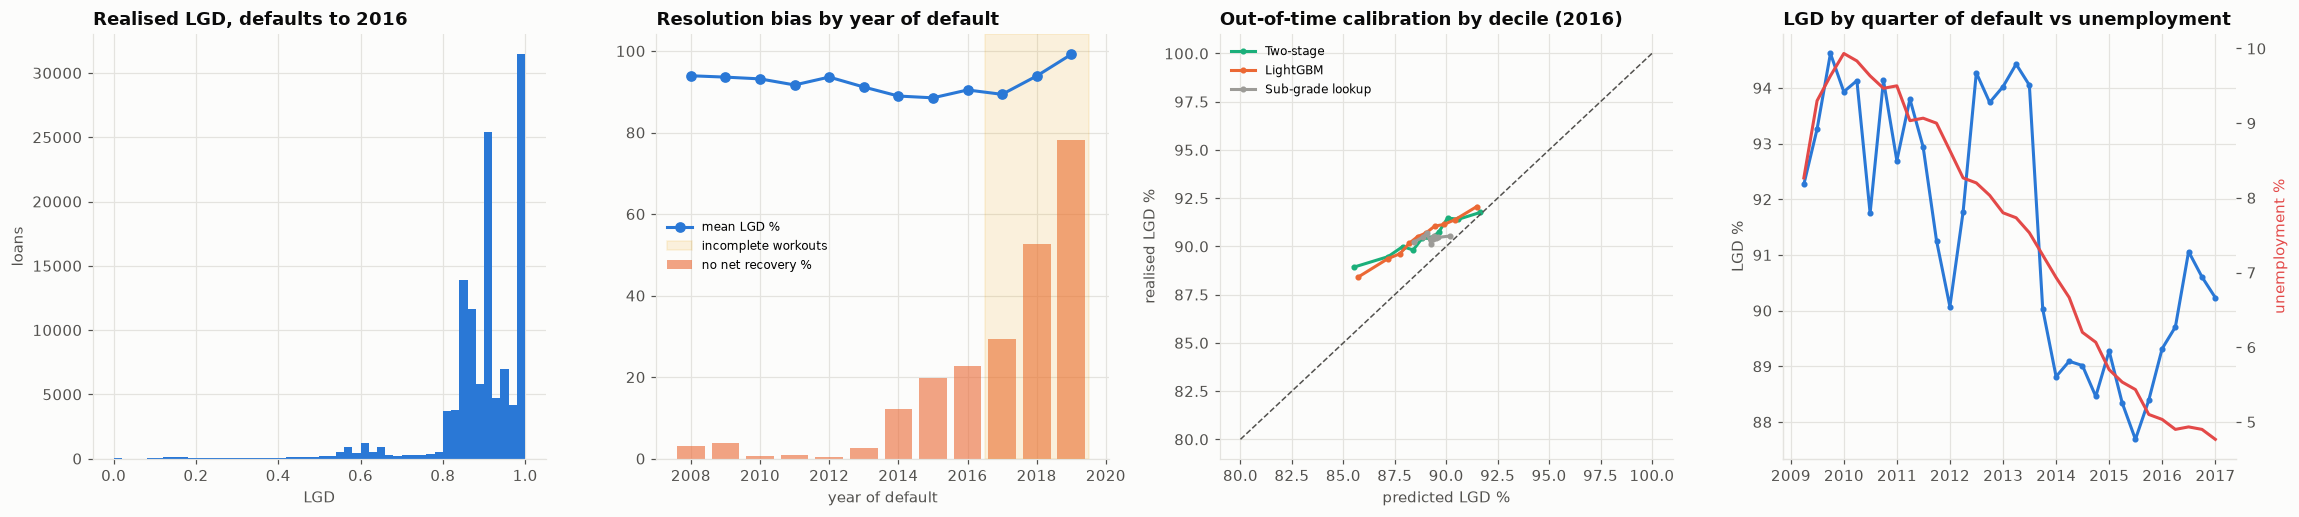

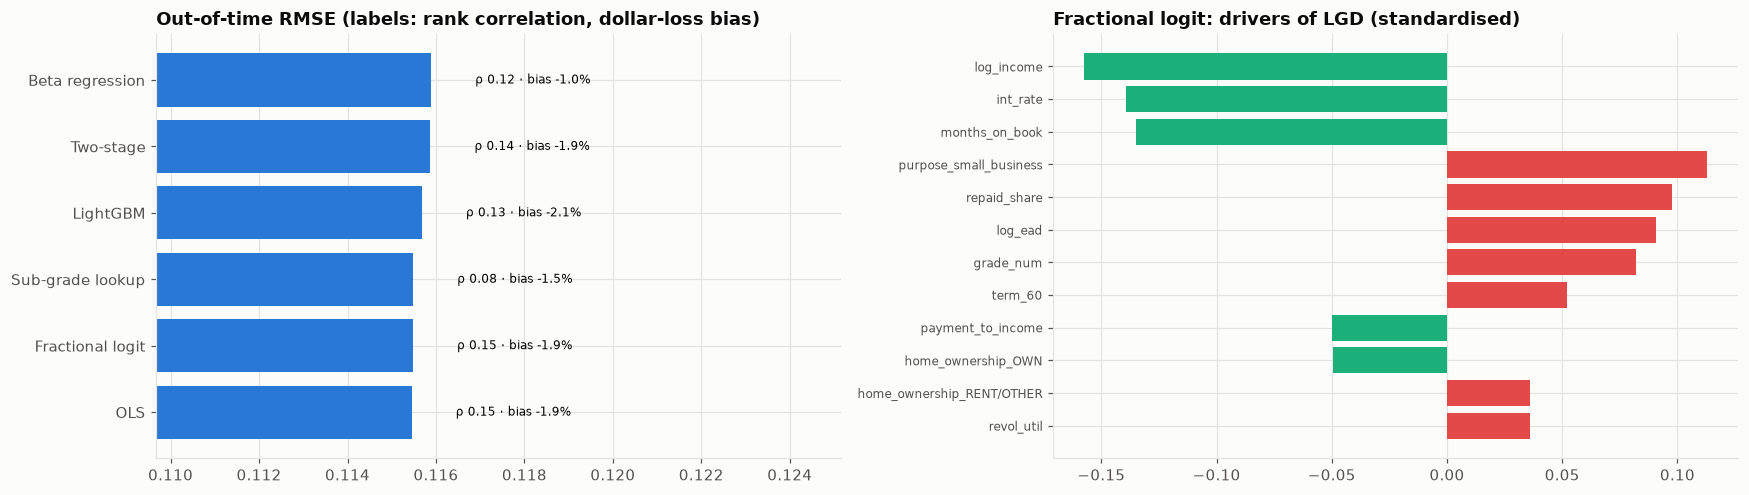

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(21, 4.8))
ax = axes[0]
ax.hist(d.loc[d["default_year"] <= TEST_YEAR, "LGD"], bins=50, color=PALETTE[0])
ax.set_title(f"Realised LGD, defaults to {TEST_YEAR}"); ax.set_xlabel("LGD"); ax.set_ylabel("loans")
ax = axes[1]
ax.bar(vint.index, vint["no_recovery"] * 100, color=PALETTE[1], alpha=0.6, label="no net recovery %")
ax.plot(vint.index, vint["mean_LGD"] * 100, "o-", color=PALETTE[0], label="mean LGD %")
ax.axvspan(TEST_YEAR + 0.5, vint.index.max() + 0.5, color=STATUS["amber"], alpha=0.12, label="incomplete workouts")
ax.set_title("Resolution bias by year of default"); ax.set_xlabel("year of default"); ax.legend(fontsize=8)
ax = axes[2]
for m, col in [("Two-stage", PALETTE[2]), ("LightGBM", PALETTE[1]), ("Sub-grade lookup", "#9c9b97")]:
    dq = pd.qcut(preds[m], 10, labels=False, duplicates="drop")
    g = pd.DataFrame({"p": preds[m], "y": yte, "q": dq}).groupby("q").mean()
    ax.plot(g["p"] * 100, g["y"] * 100, "o-", ms=3, color=col, label=m)
lo_, hi_ = 80, 100
ax.plot([lo_, hi_], [lo_, hi_], color=INK_2, ls="--", lw=1)
ax.set_title(f"Out-of-time calibration by decile ({TEST_YEAR})"); ax.set_xlabel("predicted LGD %"); ax.set_ylabel("realised LGD %"); ax.legend(fontsize=8)
ax = axes[3]
ax.plot(qd.index, qd["LGD %"], "o-", ms=3, color=PALETTE[0], label="LGD %")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(qd.index, qd["unemployment %"], color=PALETTE[7], label="unemployment %")
ax.set_title("LGD by quarter of default vs unemployment"); ax.set_ylabel("LGD %"); ax2.set_ylabel("unemployment %", color=PALETTE[7])
plt.tight_layout()
save_fig(fig, "01_lgd_distribution_bias_calibration")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(16, 4.6))
ax = axes[0]
o = oot.sort_values("RMSE")
ax.barh(o.index, o["RMSE"], color=PALETTE[0])
for i, (m, r) in enumerate(o.iterrows()):
    ax.text(r["RMSE"] + 0.001, i, f"ρ {r['Spearman ρ']:.2f} · bias {r['EAD-weighted loss error %']:+.1f}%", va="center", fontsize=8)
ax.set_xlim(o["RMSE"].min() * 0.95, o["RMSE"].max() * 1.08)
ax.set_title("Out-of-time RMSE (labels: rank correlation, dollar-loss bias)")
ax = axes[1]
c = coef["fractional logit"].head(12).iloc[::-1]
ax.barh(c.index, c.values, color=[PALETTE[7] if v > 0 else PALETTE[2] for v in c.values])
ax.set_title("Fractional logit: drivers of LGD (standardised)"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
save_fig(fig, "02_model_comparison_drivers")
plt.show()

## 10. Reading the results and limitations

269,000 charged-off Lending Club loans. Models are trained on 58,190 defaults from 2010–2015 and tested on 61,286 defaults from 2016:

- **Unsecured consumer LGD is high and tightly clustered.** Mean LGD is 91% (EAD-weighted 91%). The distribution has a spike at 100% (no net recovery for 31% of all charged-off loans), a large mass between 80% and 95%, and a small tail of settlements around 50–75%.
- **The recovery process drives LGD more than the borrower does.** By channel: debt sale or standard collection 90% LGD (152,000 loans), settlement 76%, high recovery 50%, and nothing recovered 100%. The channel mix changed a lot over the decade. The share of defaults with no net recovery went from under 1% in 2010–2012 to 12% in 2014, 23% in 2016 and 53% in 2018. Settlements grew from 1–2% to 13–15%. The collection fee jumped from about 1% to 18% of recoveries in 2015.
- **Resolution bias is visible.** Defaults in 2018 show 94% LGD and 2019 defaults 99%, because their workouts had not finished when the data were cut at the end of 2018. Using them would bias LGD up by 4–9 points. That is why the model sample stops at 2016.
- **Loan-level models explain almost nothing.** In sample, the fractional logit explains 1.7% of the variance and LightGBM 7.0%. Out of time, every model has an R² slightly below zero and a rank correlation of 0.08–0.15 with realised LGD. The sub-grade lookup has the lowest RMSE (0.115). Beta regression has the smallest dollar-loss bias (−1.0%); the others under-predict 2016 losses by 1.5–2.0%, because the no-recovery share rose from 14% in training to 23% in the test year. Stage 1 of the two-stage model ranks zero-recovery loans barely better than chance (AUC 0.58), so the hurdle structure cannot help.
- **The drivers that do exist make sense.** Higher income, longer time on book before default and higher-rate loans (given grade) recover more. Larger exposures, small-business purpose, renters and 60-month loans recover less. Whole loans (sold to institutional investors) have slightly lower LGD than fractional loans. The effects are statistically clear, with |t| between 3 and 10, but small: a one-standard-deviation move changes LGD by 1–2 points.
- **Downturn LGD cannot be identified cleanly here.** Quarterly LGD was 92–95% in 2009–2013, when unemployment was 8–10%, and 88–89% in 2014–2015. The weighted slope is +0.45 points of LGD per point of unemployment, but it is not significant (t = 1.8), and it is confounded with the operational changes above. The conservative choice is the worst four-quarter average, **94.1%**, about 4 points above the long-run 89.9%.
- **What this means for a risk officer.** For unsecured retail credit sold to debt buyers, a **pooled LGD by segment** (here by sub-grade) with a downturn add-on is as accurate as any regression. The model risk sits in the recovery process: debt-sale prices, collection fees and the share of loans never sold. Monitoring should track the channel mix and recovery timing, because those moved LGD more than any borrower characteristic.

**Limitations**

- The default date is proxied by the last payment date. The exact charge-off date and recovery timing are not public, so discounting of recoveries (part of the IRB workout-LGD definition) is not applied.
- Costs other than the collection fee (internal collection costs) are not observed, so LGD is understated relative to an economic LGD.
- Lending Club's book grew 50-fold over the sample, so early years rest on few defaults.

In [12]:
oot.to_csv(OUT_DIR / "out_of_time_validation.csv")
coef.to_csv(OUT_DIR / "lgd_drivers.csv")
vint.to_csv(OUT_DIR / "lgd_by_default_year.csv")
qd.to_csv(OUT_DIR / "downturn_lgd_quarterly.csv")
print("Outputs written:", ", ".join(sorted(p.name for p in OUT_DIR.iterdir())))

Outputs written: 01_lgd_distribution_bias_calibration.png, 02_model_comparison_drivers.png, downturn_lgd_quarterly.csv, lgd_by_default_year.csv, lgd_drivers.csv, out_of_time_validation.csv
